# COMPARING CALIBRATION METHODS FOR PREDICTING CONVERSION TO MILD COGNITIVE IMPAIRMENT

In [1]:
import numpy as np
import pandas as pd
import sklearn as skl
from sklearn.linear_model import LogisticRegression
import xgboost as xgb_model
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from scipy.special import logit, expit
from sklearn.metrics import log_loss
from sklearn.metrics import brier_score_loss

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

X_train = train.drop(columns=["EVENT_MCI"]) 
y_train = train["EVENT_MCI"]
X_test = test.drop(columns=["EVENT_MCI"]) 
y_test = test["EVENT_MCI"]

print('train shape: ', train.shape)
print('test shape: ', test.shape)


train shape:  (15108, 50)
test shape:  (3778, 50)


We loaded the train and test sets and separated the target variable from the other variables\.

In [3]:
overview = pd.DataFrame({
    'type': X_train.dtypes,                 
    'different values': X_train.nunique()    
})
overview

,type,different values
INDEPEND,float64,2
MEMORY,float64,4
ORIENT,float64,2
JUDGMENT,float64,2
COMMUN,float64,2
HOMEHOBB,float64,2
CDRSUM,float64,4
CDRGLOB,float64,4
MEMPROB,float64,2
TAXES,float64,2


We looked at the types of attributes and the number of different values\. We can see that the data has been processed, since all types are float and besides TRAILB all other attributes have a low number of different values\.

In [4]:
train_subset = train.groupby('EVENT_MCI').sample(frac=0.7, random_state=1)  # 70% of each EVENT_MCI group
valid_subset = train.drop(train_subset.index)

X_train_subset = train_subset.drop(columns=['EVENT_MCI'])
y_train_subset = train_subset['EVENT_MCI']
X_valid_subset = valid_subset.drop(columns=['EVENT_MCI'])
y_valid_subset = valid_subset['EVENT_MCI']

print('train subset:', len(X_train_subset), '  mean of EVENT_MCI:', y_train_subset.mean())
print('valid subset:', len(X_valid_subset), '  mean of EVENT_MCI:', y_valid_subset.mean())

train subset: 10575   mean of EVENT_MCI: 0.3054373522458629
valid subset: 4533   mean of EVENT_MCI: 0.30553717185087137


Then we split the train set into a train subset \(70%\) and a validation subset \(30%\) using a stratified split, so the share of patients who developed MCI was the same in both subsets\.

# 

# ML models

In [5]:
lr = LogisticRegression(random_state=1)
rf = skl.ensemble.RandomForestClassifier(random_state=1)
xgb = xgb_model.XGBClassifier(random_state=1)

### Training models

In [6]:
lr.fit(X_train_subset, y_train_subset)
rf.fit(X_train_subset, y_train_subset)
xgb.fit(X_train_subset, y_train_subset)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

### Probabilities

In [7]:
probabilities = lr.predict_proba(X_valid_subset) # probabilites for every patient
prob_valid_lr = probabilities[:, 1]   # probabilities only for patients who get MCI (column 1)

probabilities = lr.predict_proba(X_test)
prob_test_lr = probabilities[:, 1]

print(prob_valid_lr)
print('AUC for validation: ', roc_auc_score(y_valid_subset, prob_valid_lr))
print(prob_test_lr)
print('AUC for test: ', roc_auc_score(y_test, prob_test_lr))

[7.41557515e-01 2.00532171e-04 4.50951106e-04 ... 1.95538301e-04
 1.58079129e-04 6.80880375e-01]
AUC for validation:  0.920096766498929
[7.27539135e-01 5.82554022e-01 8.79413282e-02 ... 1.93657911e-01
 6.96617697e-01 1.63168181e-04]
AUC for test:  0.9207349528550809


In [8]:
probabilities = rf.predict_proba(X_valid_subset) 
prob_valid_rf = probabilities[:, 1]   

probabilities = rf.predict_proba(X_test)
prob_test_rf = probabilities[:, 1]

print(prob_valid_rf)
print('AUC for validation: ', roc_auc_score(y_valid_subset, prob_valid_rf))
print(prob_test_rf)
print('AUC for test: ', roc_auc_score(y_test, prob_test_rf))

[0.74 0.   0.   ... 0.   0.   0.51]
AUC for validation:  0.9172433130427203
[0.76 0.32 0.02 ... 0.16 0.53 0.  ]
AUC for test:  0.9111825751572825


In [9]:
probabilities = xgb.predict_proba(X_valid_subset) 
prob_valid_xgb = probabilities[:, 1]   

probabilities = xgb.predict_proba(X_test)
prob_test_xgb = probabilities[:, 1]

print(prob_valid_xgb)
print('AUC for validation: ', roc_auc_score(y_valid_subset, prob_valid_xgb))
print(prob_test_xgb)
print('AUC for test: ', roc_auc_score(y_test, prob_test_xgb))

[9.0201938e-01 1.4881010e-04 1.8439295e-04 ... 8.7883149e-05 5.3063031e-05
 7.9624933e-01]
AUC for validation:  0.9098588754994288
[7.1099257e-01 5.0770950e-01 3.5508525e-02 ... 6.2335160e-02 6.7811793e-01
 5.7569021e-05]
AUC for test:  0.9076103302306572


# 

# Calibration methods

## Isotonic regression

Isotonic regression makes a table showing what the model told the patients and if they really did get MCI\. The table's range is from the smallest to the biggest value\. If the patient has a value outside of the range, the value changes either to minimum or maximum \- that's what clip is for\.

### for Logistic regression:

In [10]:
iso_lr = IsotonicRegression(out_of_bounds="clip")
iso_lr.fit(prob_valid_lr, y_valid_subset)
prob_test_lr_iso = iso_lr.predict(prob_test_lr)

In [11]:
test_points = np.array([0.05, 0.3, 0.5, 0.9])
print('LR: ', iso_lr.predict(test_points))

LR:  [0.         0.35795455 0.61025641 0.89247312]


For logistic regression, isotonic regression lowered the low probabilities \(0\.05 changed to 0\), increased the middle ones \(0\.3 changed to 0\.358 and 0\.5 changed to 0\.610\) and the high probabilities changed only a little \(0\.9 changed to 0\.892\)

### for Random forest:

In [12]:
iso_rf = IsotonicRegression(out_of_bounds="clip")
iso_rf.fit(prob_valid_rf, y_valid_subset)
prob_test_rf_iso = iso_rf.predict(prob_test_rf)

In [13]:
test_points = np.array([0.05, 0.3, 0.5, 0.9])
print('RF: ', iso_rf.predict(test_points))

RF:  [0.04545455 0.27272727 0.52380952 0.84158416]


For random forest, the low and middle probabilities changed only slightly \(0\.05 changed to 0\.045, 0\.3 changed to 0\.273 and 0\.5 changed to 0\.524\) and the high probabilities lowered a bit more \(0\.9 changed to 0\.842\)

### for XGBoost:

In [14]:
iso_xgb = IsotonicRegression(out_of_bounds="clip")
iso_xgb.fit(prob_valid_xgb, y_valid_subset)
prob_test_xgb_iso = iso_xgb.predict(prob_test_xgb)

In [15]:
test_points = np.array([0.05, 0.3, 0.5, 0.9])
print('XGB:', iso_xgb.predict(test_points))

XGB: [0.10502283 0.42307693 0.53333336 0.8209459 ]


For XGBoost, isotonic regression pulled the probabilities towards the middle: the low probabilities increased \(0\.05 changed to 0\.105\) and the high probabilities lowered \(0\.9 changed to 0\.821\)\.

## Temperature scaling

In [16]:
def adjust(probability, T): 
    # 0 gets changed to 0.000001, and 1 gets changed to 0.999999, because logit(0) and logit(1) would be infinite
    probability = np.clip(probability, 0.000001, 0.999999) 
    # logit - converts the probability to a score, where the middle value is 0 (0.5 -> 0, 0.9 -> 2.2, 0.1 -> -2.2)
    # T: shrinks the score towards 0 (T>1) or streches it away from 0 (T<1)
    # expit: converts the score back to probability
    return expit(logit(probability) / T)

The function adjust changes the probability based on the selected T\. T is selected based on the function log\_loss, which tells us how bad the predictions are \- so the smaller the value of log\_loss, the better\. This function also adjusts the numbers 0 and 1 to 0\.000001 and 0\.999999, because logit\(0\) and logit\(1\) would be infinite\.

### for Logistic regression:

In [17]:
results = []
for T in np.linspace(0.1, 5, 50):  # (the start, the end, the number of values)
    p = adjust(prob_valid_lr, T)
    results.append((T, log_loss(y_valid_subset, p)))

results = pd.DataFrame(results, columns=['T', 'log_loss'])
best_T_lr = results.loc[results['log_loss'].idxmin(), 'T']
print(results)
print('best T for LR:', best_T_lr)

      T  log_loss
0   0.1  1.234952
1   0.2  0.652415
2   0.3  0.473121
3   0.4  0.393946
4   0.5  0.353892
5   0.6  0.332500
6   0.7  0.321023
7   0.8  0.315169
8   0.9  0.312646
9   1.0  0.312157
10  1.1  0.312944
11  1.2  0.314552
12  1.3  0.316703
13  1.4  0.319224
14  1.5  0.322006
15  1.6  0.324981
16  1.7  0.328101
17  1.8  0.331337
18  1.9  0.334665
19  2.0  0.338069
20  2.1  0.341536
21  2.2  0.345054
22  2.3  0.348612
23  2.4  0.352203
24  2.5  0.355818
25  2.6  0.359449
26  2.7  0.363088
27  2.8  0.366730
28  2.9  0.370369
29  3.0  0.373998
30  3.1  0.377612
31  3.2  0.381207
32  3.3  0.384778
33  3.4  0.388321
34  3.5  0.391834
35  3.6  0.395313
36  3.7  0.398756
37  3.8  0.402159
38  3.9  0.405522
39  4.0  0.408843
40  4.1  0.412120
41  4.2  0.415351
42  4.3  0.418537
43  4.4  0.421677
44  4.5  0.424769
45  4.6  0.427814
46  4.7  0.430812
47  4.8  0.433762
48  4.9  0.436664
49  5.0  0.439518
best T for LR: 1.0


We tried 50 differents values for T, ranging from 0\.1 to 5, and the T with the smallest log\_loss is the best one\. For logistic regression the best T was 1, which means that its probabilities are neither overconfident nor underconfident, so temperature scaling had nothing to correct\.

In [18]:
prob_test_lr_ts = adjust(prob_test_lr, best_T_lr)

Then we used the best T on the test data\.

### for Random forest:

In [19]:
results = []
for T in np.linspace(0.1, 5, 50): 
    p = adjust(prob_valid_rf, T)
    results.append((T, log_loss(y_valid_subset, p)))

results = pd.DataFrame(results, columns=['T', 'log_loss'])
best_T_rf = results.loc[results['log_loss'].idxmin(), 'T']
print(results)
print('best T for RF:', best_T_rf)

      T  log_loss
0   0.1  1.314479
1   0.2  0.703392
2   0.3  0.513630
3   0.4  0.428342
4   0.5  0.381588
5   0.6  0.355417
6   0.7  0.340359
7   0.8  0.331786
8   0.9  0.327202
9   1.0  0.325166
10  1.1  0.324797
11  1.2  0.325539
12  1.3  0.327023
13  1.4  0.329003
14  1.5  0.331313
15  1.6  0.333834
16  1.7  0.336487
17  1.8  0.339216
18  1.9  0.341981
19  2.0  0.344757
20  2.1  0.347526
21  2.2  0.350275
22  2.3  0.352998
23  2.4  0.355691
24  2.5  0.358352
25  2.6  0.360980
26  2.7  0.363576
27  2.8  0.366140
28  2.9  0.368675
29  3.0  0.371182
30  3.1  0.373662
31  3.2  0.376116
32  3.3  0.378547
33  3.4  0.380956
34  3.5  0.383343
35  3.6  0.385711
36  3.7  0.388058
37  3.8  0.390387
38  3.9  0.392698
39  4.0  0.394991
40  4.1  0.397267
41  4.2  0.399525
42  4.3  0.401767
43  4.4  0.403992
44  4.5  0.406199
45  4.6  0.408390
46  4.7  0.410564
47  4.8  0.412721
48  4.9  0.414861
49  5.0  0.416983
best T for RF: 1.1


The best T was 1\.1, but the log\_loss for T = 1 \(0\.3252\) and T = 1\.1 \(0\.3248\) is almost the same\. This means that random forest is only very slightly overconfident and temperature scaling doesn't really change its probabilities\.

In [20]:
prob_test_rf_ts = adjust(prob_test_rf, best_T_rf)

### for XGBoost:

In [21]:
results = []
for T in np.linspace(0.1, 5, 50): 
    p = adjust(prob_valid_xgb, T)
    results.append((T, log_loss(y_valid_subset, p)))

results = pd.DataFrame(results, columns=['T', 'log_loss'])
best_T_xgb = results.loc[results['log_loss'].idxmin(), 'T']
best_T_xgb = round(best_T_xgb, 2)
print(results)
print('best T for XGB:', best_T_xgb)

      T  log_loss
0   0.1  1.882349
1   0.2  0.976144
2   0.3  0.682565
3   0.4  0.543865
4   0.5  0.466507
5   0.6  0.419326
6   0.7  0.388982
7   0.8  0.368826
8   0.9  0.355195
9   1.0  0.345926
10  1.1  0.339672
11  1.2  0.335563
12  1.3  0.333022
13  1.4  0.331652
14  1.5  0.331177
15  1.6  0.331402
16  1.7  0.332180
17  1.8  0.333406
18  1.9  0.334998
19  2.0  0.336892
20  2.1  0.339037
21  2.2  0.341393
22  2.3  0.343925
23  2.4  0.346606
24  2.5  0.349410
25  2.6  0.352318
26  2.7  0.355311
27  2.8  0.358373
28  2.9  0.361491
29  3.0  0.364652
30  3.1  0.367846
31  3.2  0.371062
32  3.3  0.374293
33  3.4  0.377531
34  3.5  0.380769
35  3.6  0.384001
36  3.7  0.387223
37  3.8  0.390429
38  3.9  0.393616
39  4.0  0.396780
40  4.1  0.399918
41  4.2  0.403027
42  4.3  0.406106
43  4.4  0.409153
44  4.5  0.412165
45  4.6  0.415141
46  4.7  0.418080
47  4.8  0.420982
48  4.9  0.423845
49  5.0  0.426670
best T for XGB: 1.5


For XGBoost the best T was 1\.5, which is higher than in logistic regression \(1\.0\) and random forest \(1\.1\)\. The log\_loss decreased from 0\.3459 \(T = 1\.0\) to 0\.3312 \(T = 1\.5\), so there is a clear minimum\. This means that XGBoost was overconfident and temperature scaling shrinks its probabilities towards 0\.5\.

In [22]:
prob_test_xgb_ts = adjust(prob_test_xgb, best_T_xgb)

## Beta calibration

In [23]:
def transform_bc(probability):
    probability = np.clip(probability, 0.000001, 0.999999)
    # makes 2 new columns for every patient - log(probability) (important for low probabilites)
    # and -log(1-probability) (important for high probabilities)
    return np.column_stack([np.log(probability), -np.log(1 - probability)])

The function transform\_bc makes from one probability two new numbers, so the logistic regression can learn a seperate weight for low and for high probabilities\.

### for Logistic regression:

In [24]:
# logistic regression without regularization (penalty=None)
beta_lr = LogisticRegression(penalty=None)
# learning on the validation subset: input = two numbers for every patient, output = 0 or 1 (did the patient get MCI)
beta_lr.fit(transform_bc(prob_valid_lr), y_valid_subset)

# using the learned model on the test set, [:, 1] -> probability that the patient has MCI (in opposed to doesn't -> [:, 0])
prob_test_lr_beta = beta_lr.predict_proba(transform_bc(prob_test_lr))[:, 1]

# number found by the function fit: a = weight of log(probability), b = weight of -log(1-probability), c = shift
print('a =', beta_lr.coef_[0][0])
print('b =', beta_lr.coef_[0][1])
print('c =', beta_lr.intercept_[0])

a = 1.4641472498936676
b = 0.5369292217040974
c = 0.8060690507770116


Beta calibration changes the probability to expit\(a \* log\(probability\) \- b \* log\(1\-probability\) \+ c\)\. We looked for the three numbers \(a, b, c\) that adjust the probabilities the best, using a logistic regression on the validation subset\. It gets the two numbers from transform\_bc for every patient and compares the adjusted probabilities with what really happened \(whether the patient developed MCI\)\. We got a = 1\.464, b = 0\.537 and c = 0\.806 and used them on the test data\. 

In [25]:
test_points = np.array([0.05, 0.3, 0.5, 0.9])
print('LR:', beta_lr.predict_proba(transform_bc(test_points))[:, 1])

LR: [0.02785254 0.31751506 0.54075202 0.86854228]


The probabilities around the middle changed only a little, but the very low probabilities were lowered \(for example 0\.05 changed to 0\.028\)\.

### for Random forest:

In [26]:
beta_rf = LogisticRegression(penalty=None)
beta_rf.fit(transform_bc(prob_valid_rf), y_valid_subset)

prob_test_rf_beta = beta_rf.predict_proba(transform_bc(prob_test_rf))[:, 1]

print('a =', beta_rf.coef_[0][0])
print('b =', beta_rf.coef_[0][1])
print('c =', beta_rf.intercept_[0])

a = 0.8794810145194797
b = 0.995192387714712
c = -0.030228025738795843


In [27]:
test_points = np.array([0.05, 0.3, 0.5, 0.9])
print('RF:', beta_rf.predict_proba(transform_bc(test_points))[:, 1])

RF: [0.06825102 0.3242871  0.51249165 0.89739639]


We did the same for random forest and got a = 0\.879, b = 0\.995, c = \-0\.030\. These numbers are close to a = 1, b = 1 and c = 0, which would not change the probabilities at all\. Only the low probabilities changed slightly \(for example 0\.05 changed to 0\.068\)\.

### for XGBoost:

In [28]:
beta_xgb = LogisticRegression(penalty=None)
beta_xgb.fit(transform_bc(prob_valid_xgb), y_valid_subset)

prob_test_xgb_beta = beta_xgb.predict_proba(transform_bc(prob_test_xgb))[:, 1]

print('a =', beta_xgb.coef_[0][0])
print('b =', beta_xgb.coef_[0][1])
print('c =', beta_xgb.intercept_[0])

a = 0.8710475542101859
b = 0.38461182857916626
c = 0.523604834814239


In [29]:
test_points = np.array([0.05, 0.3, 0.5, 0.9])
print('XGB:', beta_xgb.predict_proba(transform_bc(test_points))[:, 1])

XGB: [0.1124364  0.40421539 0.54647379 0.78875419]


For XGBoost we got a = 0\.871, b = 0\.385 and c = 0\.524\. Both a and b are smaller than 1, which means that the probabilities were pulled towards the middle, because it was overconfident, like it was in temperature scaling with T \> 1\. This means that the low probabilities were increased \(for example 0\.05 changed to 0\.112\) and the high probabilities were lowered \(for example 0\.9 changed to 0\.789\)\.

# 

# Metrics

In [30]:
def ece(y, prob):
    # table with the predicted probability and the real outcome (0/1) for every patient
    df = pd.DataFrame({"predicted": prob, "real": np.array(y)})

    # bin number 0-9 for every patient (0.37 -> 3, 0.92 -> 9)
    bins = []
    for p in prob:
        b = int(p * 10) 
        if b == 10:  # probability 1.0 would be bin 10
            b = 9  # so it goes to the last bin
        bins.append(b)
    df["bin"] = bins  # add the bin numbers as a new column

    total = 0  # here we add up the errors of all bins
    for b in range(10):  # go through bins 0, 1, ..., 9
        in_bin = df[df["bin"] == b]  # patients in this bin
        if len(in_bin) > 0:  
            predicted = in_bin["predicted"].mean() 
            real = in_bin["real"].mean() 
            weight = len(in_bin) / len(df)  # how many % of of all patients is in this bin
            total += weight * abs(predicted - real)  
    return total  

The function ece calculates how much the predicted probabilities differ from reality on average\.  For example, an ECE of 0\.02 means that the predicted probabilities are on average about 2 percentage points away from the real share of patients who developed MCI\. The lower the ECE, the better the model is calibrated\.

In [31]:
# every row: model, calibration method, test probabilities
predictions = [
    ["Logistic regression", "Uncalibrated",        prob_test_lr],
    ["Logistic regression", "Temperature scaling", prob_test_lr_ts],
    ["Logistic regression", "Beta calibration",    prob_test_lr_beta],
    ["Logistic regression", "Isotonic regression", prob_test_lr_iso],
    ["Random forest",       "Uncalibrated",        prob_test_rf],
    ["Random forest",       "Temperature scaling", prob_test_rf_ts],
    ["Random forest",       "Beta calibration",    prob_test_rf_beta],
    ["Random forest",       "Isotonic regression", prob_test_rf_iso],
    ["XGBoost",             "Uncalibrated",        prob_test_xgb],
    ["XGBoost",             "Temperature scaling", prob_test_xgb_ts],
    ["XGBoost",             "Beta calibration",    prob_test_xgb_beta],
    ["XGBoost",             "Isotonic regression", prob_test_xgb_iso],
]

rows = []  # here we collect one row of results for every set
for model, method, prob in predictions:  # take one row of the list at a time
    rows.append({
        "Model": model,
        "Method": method,
        "ECE": ece(y_test, prob), 
        "Brier": brier_score_loss(y_test, prob),  # overall error of the probabilities (lower = better)
        "AUC": roc_auc_score(y_test, prob),  # ability to distinguish patients (should stay the same)
    })

# turn the list into a table
results_table = pd.DataFrame(rows)
results_table

,Model,Method,ECE,Brier,AUC
0,Logistic regression,Uncalibrated,0.012936,0.105773,0.920735
1,Logistic regression,Temperature scaling,0.012936,0.105773,0.920735
2,Logistic regression,Beta calibration,0.017334,0.105992,0.920735
3,Logistic regression,Isotonic regression,0.013645,0.106536,0.919782
4,Random forest,Uncalibrated,0.017785,0.111570,0.911183
5,Random forest,Temperature scaling,0.017095,0.111499,0.911183
6,Random forest,Beta calibration,0.015788,0.111498,0.911183
7,Random forest,Isotonic regression,0.013716,0.111854,0.910722
8,XGBoost,Uncalibrated,0.041627,0.117157,0.907610
9,XGBoost,Temperature scaling,0.018578,0.114656,0.907610


We put all 12 sets of test probabilities \(3 models, each uncalibrated \+ 3 calibration methods\) into one list\. For each of them, we calculated the ECE, the Brier score and the AUC on the test set and saved the results into a table\.

- Logistic regression was already well calibrated without calibration \(ECE 0\.013\) and no calibration method improved it\. Temperature scaling did not change anything \(T = 1\), beta calibration slightly increased the ECE and isotonic regression kept it almost the same\.

- Random forest was slightly worse calibrated \(ECE 0\.018\) and all the methods improved it a little\. Isotonic regression lowered it the most \(ECE 0\.014\), beta calibration was the second best \(ECE 0\.016\) and temperature scaling made the smallest change \(ECE 0\.017\)\.

- XGBoost was the worst calibrated model \(ECE 0\.042\), which corresponds to it being overconfident \(T = 1\.5\)\. All three methods clearly improved it: temperature scaling lowered ECE to 0\.019, beta calibration to 0\.013 and isotonic regression to 0\.012\. 

The AUC stayed almost the same for all methods, only isotonic regression slightly lowered it\.

For logistic regression and random forest, isotonic regression had the lowest ECE but a slightly higher Brier score, which shows that the two metrics do not always agree\.

In [32]:
def reliability_points(y, prob):
    # table with the predicted probability and the real outcome (0/1) for every patient
    df = pd.DataFrame({"predicted": prob, "real": np.array(y)})

    # same bins as in ece (0.37 -> 3, 0.92 -> 9, 1.0 -> 9)
    bins = []
    for p in prob:
        b = int(p * 10)
        if b == 10:
            b = 9
        bins.append(b)
    df["bin"] = bins

    x, y_points = [], []  # x = average predictions, y_points = real shares of MCI
    for b in range(10):
        in_bin = df[df["bin"] == b]  
        if len(in_bin) >= 10:  # skip bins with too few patients
            x.append(in_bin["predicted"].mean())  
            y_points.append(in_bin["real"].mean())  
    return x, y_points  # points of the line in the reliability diagram

The function reliability\_points uses the same bins as the ECE\. For every bin, it returns the average predicted probability \(x\) and the real share of patients who developed MCI \(y\)\. Bins with fewer than 10 patients are skipped, because their results would not be reliable\.

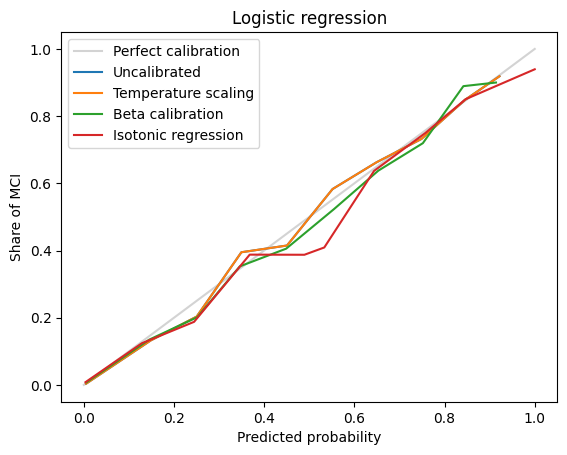

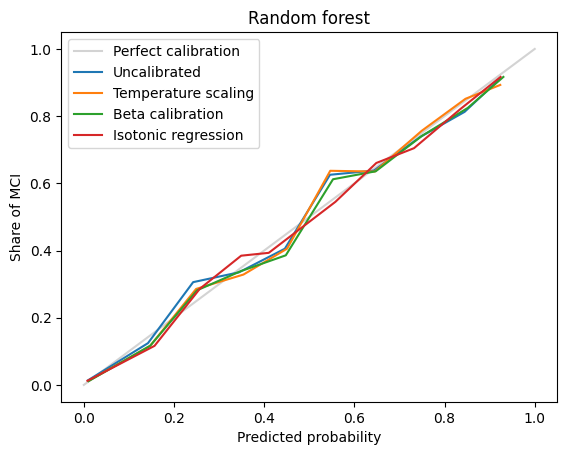

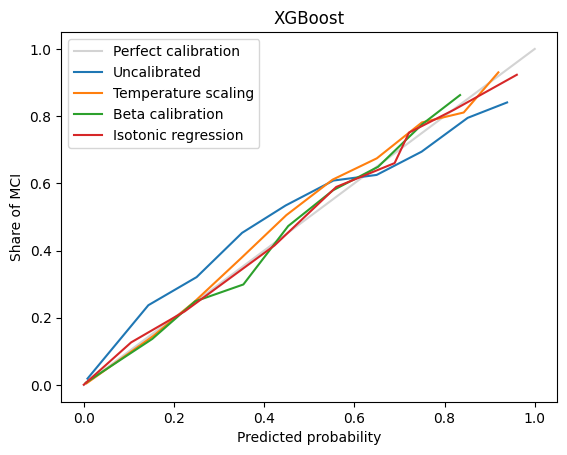

In [33]:
models = ["Logistic regression", "Random forest", "XGBoost"]

for model_name in models:  # one image for every model
    # diagonal = perfect calibration
    plt.plot([0, 1], [0, 1], color="lightgray", label="Perfect calibration")
    for model, method, prob in predictions:  # go through all 12 sets
        if model == model_name: 
            x, y_points = reliability_points(y_test, prob)  # points of the line
            plt.plot(x, y_points, label=method)  # draw the line
    plt.title(model_name)  # title of the figure = model name
    plt.xlabel("Predicted probability")
    plt.ylabel("Share of MCI")
    plt.legend()  # show which line is which method
    plt.savefig(f"reliability_{model_name}.png", dpi=300)  # save in high quality for the paper
    plt.show()  

We drew a reliability diagram for every model\. The grey diagonal shows perfect calibration, where the predicted probability equals the real share of patients with MCI\. Each line shows one calibration method\. The closer a line is to the diagonal, the better calibrated the probabilities are\.

### Logistic regression: 

- The uncalibrated line is not visible, because it is covered by the temperature scaling line \- since the best T is one, temperature scaling did not change the probabilities, so both lines are the same\. They are close to the diagonal, with small deviations from 0\.25 to 0\.55\. 

- Beta calibration made the line closer to the diagonal in the middle, but moved it slightly away for high probabilities \(below it around 0\.75 and above it around 0\.85\), which explains the higher ECE\.

- Isotonic regression stayed close to the diagonal for low and high probabilities, but it is below the diagonal between 0\.4 and 0\.55, where it overestimates the probabilities\.

### Random forest:

- The uncalibrated line is close to the diagonal, but it is above it around 0\.25 and 0\.55, which means that the model slightly underestimated the probabilities there\.

- Temperature scaling \(T = 1\.1\) almost did not change the line\. It only very slightly lowered the line at 0\.25, and very slighly moved up at 0\.55\.

- Beta calibration moved the line slightly closer to the diagonal around 0\.25, and very slightly around 0\.55\.

- Isotonic regression was the closest to the diagonal overall, which corresponds to its lowest ECE, although it is slightly above the diagonal between 0\.35 and 0\.4\.

### XGBoost:

- The uncalibrated line is clearly above the diagonal for low and middle probabilities and below it for high probabilities\. This means that the model's predictions were too extreme \- the model was overconfident\.

- Temperature scaling \(T = 1\.5\) moved the line much closer to the diagonal, but it is still slightly above it in the middle probabilities and below it around 0\.85\.

- Beta calibration brought the line close to the diagonal, with a small deviation below it around 0\.35\.

- Isotonic regression was the closest to the diagonal across the whole range, which corresponds to its lowest ECE\.

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=f16ed9e9-1fd6-4157-b5a8-797303124f2e' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>